# Practical 4: Matrix Addition (Pattern 2 + Multithreading)

### 1. Aim
To add three independent pairs of large matrices using Sequential, multiprocessing.Pool, multiprocessing.Process, and Multithreading.

### 2. Algorithm / Explanation
1. Generate three independent pairs of integer matrices.<br>2. Perform element-wise addition C = A + B.<br>3. Sequential: add Pair 1 -> Pair 2 -> Pair 3 sequentially.<br>4. Pool: distribute across 3 workers in `mp.Pool(3)`.<br>5. Process: spawn 3 independent `mp.Process` instances.<br>6. Thread: launch 3 concurrent `threading.Thread` workers.<br>7. Compare wall-clock execution times and speedups.

### 3. Python Implementation


In [1]:
"""
Practical 4: Matrix Addition (Pattern 2 + Multithreading)
Four methods: Sequential, Pool, Process, Thread
"""
import multiprocessing as mp
import threading
import time
import numpy as np
import matplotlib.pyplot as plt

def matrix_add_task(task):
    rows, cols, seed = task
    rng = np.random.default_rng(seed)
    A = rng.integers(1, 100, size=(rows, cols))
    B = rng.integers(1, 100, size=(rows, cols))
    C = A + B
    return int(C[0, 0])

def proc_worker(task, q):
    q.put(matrix_add_task(task))

def thread_worker(task, results, idx):
    results[idx] = matrix_add_task(task)

def main():
    print("=" * 60)
    print("Practical 4: Matrix Addition")
    print("=" * 60)
    ROWS, COLS = 5500, 5500
    tasks = [(ROWS, COLS, 101), (ROWS, COLS, 202), (ROWS, COLS, 303)]
    
    # 1. Sequential: Task 1 -> Task 2 -> Task 3
    t0 = time.perf_counter()
    r1 = matrix_add_task(tasks[0])
    r2 = matrix_add_task(tasks[1])
    r3 = matrix_add_task(tasks[2])
    t_seq = time.perf_counter() - t0
    
    # 2. Pool: 3 workers
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        p_res = pool.map(matrix_add_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # 3. Process: 3 independent processes
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    pr_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    # 4. Multithreading: 3 threads
    th_res = [None] * 3
    threads = []
    t0 = time.perf_counter()
    for i, t in enumerate(tasks):
        th = threading.Thread(target=thread_worker, args=(t, th_res, i))
        threads.append(th)
        th.start()
    for th in threads:
        th.join()
    t_thread = time.perf_counter() - t0
    
    print(f"Matrix Dimension: {ROWS}x{COLS} integers per task")
    print(f"[Sequential] Sample: {r1} | Time: {t_seq:.4f}s")
    print(f"[Pool]       Sample: {p_res[0]} | Time: {t_pool:.4f}s")
    print(f"[Process]    Sample: {pr_res[0]} | Time: {t_proc:.4f}s")
    print(f"[Thread]     Sample: {th_res[0]} | Time: {t_thread:.4f}s")
    
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    
    print("-" * 45)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 45)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 45)
    
    colors = ['#e74c3c', '#3498db', '#2ecc71', '#9b59b6']
    plt.figure(figsize=(8, 5))
    bars = plt.bar(methods, times, color=colors)
    plt.title("Execution Time Comparison (Matrix Addition)", fontsize=13)
    plt.ylabel("Time (seconds)", fontsize=11)
    for bar in bars:
        h = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, h + 0.02, f"{h:.4f}s", ha='center', va='bottom', fontsize=10)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.savefig("04_matrix_addition_time.png", dpi=150)
    plt.close()
    
    plt.figure(figsize=(8, 5))
    plt.plot(methods, speedups, marker='o', linewidth=2.5, markersize=8, color='#2980b9', label='Speedup')
    plt.title("Speedup Comparison relative to Sequential", fontsize=13, fontweight='bold')
    plt.xlabel("Method", fontsize=11)
    plt.ylabel("Speedup Factor (x)", fontsize=11)
    max_s = max(speedups) if speedups else 1.0
    plt.ylim(0, max_s * 1.25)
    for i, s in enumerate(speedups):
        plt.text(i, s + (max_s * 0.02), f"{s:.2f}x", ha='center', va='bottom', fontsize=10, fontweight='bold')
    plt.axhline(1.0, color='gray', linestyle='--', label='Baseline (1.0x)')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend(loc='upper left')
    plt.tight_layout()
    plt.savefig("04_matrix_addition_speedup.png", dpi=150)
    plt.close()
    print("Graphs saved as '04_matrix_addition_time.png' and '04_matrix_addition_speedup.png'.")

if __name__ == "__main__":
    main()


Practical 4: Matrix Addition
Matrix Dimension: 5500x5500 integers per task
[Sequential] Sample: 55 | Time: 1.0997s
[Pool]       Sample: 55 | Time: 1.0082s
[Process]    Sample: 55 | Time: 1.1088s
[Thread]     Sample: 55 | Time: 0.4620s
---------------------------------------------
Method       Execution Time     Speedup   
---------------------------------------------
Sequential   1.0997 seconds      1.00x
Pool         1.0082 seconds      1.09x
Process      1.1088 seconds      0.99x
Thread       0.4620 seconds      2.38x
---------------------------------------------
Graphs saved as '04_matrix_addition_time.png' and '04_matrix_addition_speedup.png'.


### 4. Output Graphs

#### A. Execution Time Comparison
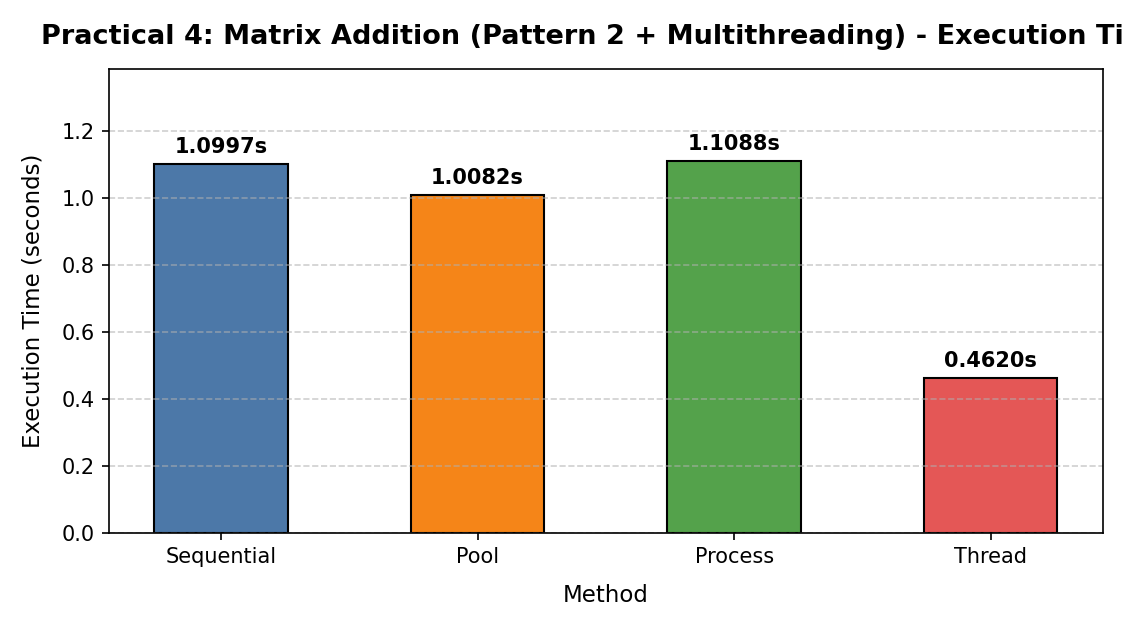

#### B. Speedup Comparison relative to Sequential
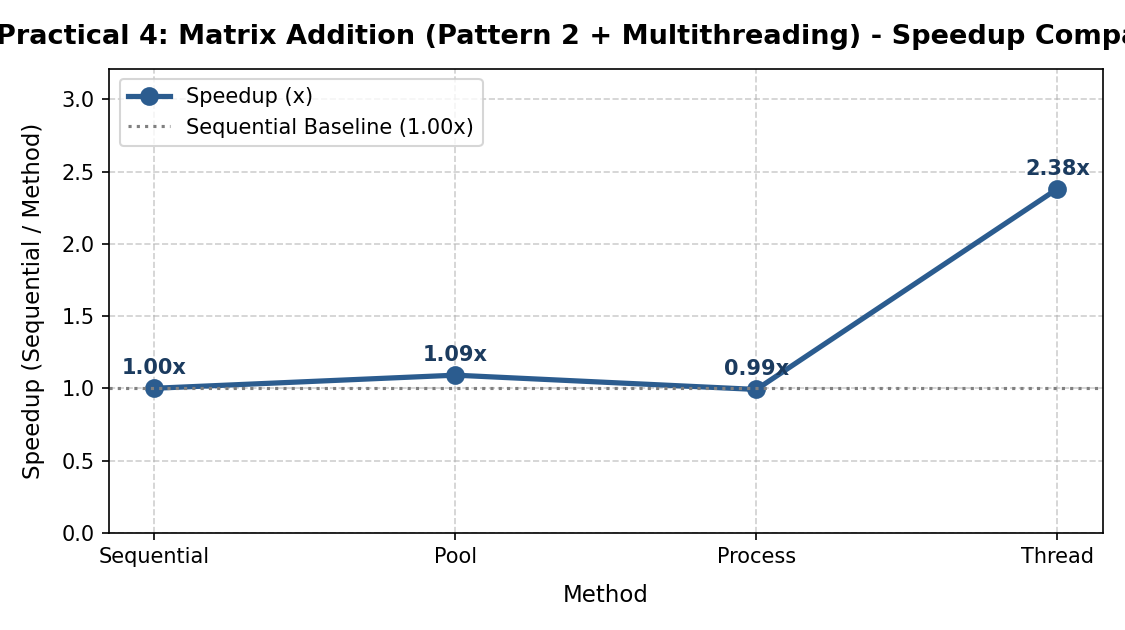
